cleaning the datset following the steps in the lab-02

In [1]:
# STUDENT INFO 
# NAME: ARBAB ALI KHOSO 
# CMS-ID: 023-24-0200
# SECTION: F
# GITHUB REPO LINK: https://github.com/ArbabAliKhoso01/Machine-Learning-Labs-semester-05
# KAGGLE PROFILE: 
# DATSET INFORMATION: 
import pandas as pd
import numpy as np 
df=pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
print(f"The no of the customers are:{df.shape[0]}\nNo: of the features in the datset are:{df.shape[1]}")
numeric=df.describe(include=["number"]).columns.tolist()
categorical=df.describe(include=["object","category"]).columns.tolist()
print(f"Numerical featres are:\n{numeric}\nCategorical Features are:\n{categorical}")
print("columns which are identifiers are:",df["customerID"])
print()
# the feature TotalCharges which has the floatin point values but its
# data type is String , this is the columns 
print(f"The data type of TotalCharges is:{df["TotalCharges"].dtype} \nand it represents the values are:\n{df["TotalCharges"].head()}")
print(f"Three Categorical columns and their uniques values are:\n1.Gender:\n{df["gender"].unique()}\n2.Partner:\n{df["Partner"].unique()}\n3.Device Protection:\n{df["DeviceProtection"].unique()}")
# the columns with suspicious or inconsistently ,scaled vlaues are:


The no of the customers are:7043
No: of the features in the datset are:21
Numerical featres are:
['SeniorCitizen', 'tenure', 'MonthlyCharges']
Categorical Features are:
['customerID', 'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges', 'Churn']
columns which are identifiers are: 0       7590-VHVEG
1       5575-GNVDE
2       3668-QPYBK
3       7795-CFOCW
4       9237-HQITU
           ...    
7038    6840-RESVB
7039    2234-XADUH
7040    4801-JZAZL
7041    8361-LTMKD
7042    3186-AJIEK
Name: customerID, Length: 7043, dtype: str

The data type of TotalCharges is:str 
and it represents the values are:
0      29.85
1     1889.5
2     108.15
3    1840.75
4     151.65
Name: TotalCharges, dtype: str
Three Categorical columns and their uniques values are:
1.Gender:
<StringArray>
['Female', 'Male

/tmp/ipykernel_80413/2227305310.py:13: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical=df.describe(include=["object","category"]).columns.tolist()


Investigating the data quality (lab-02)

In [2]:
print(f"the missing values per column are:\n{df.isnull().sum()}")
print(f"the percentage missing per column is:\n{df.isnull().sum()*100}%")
# there are no missing values in the dataset as it is obvious from the datset 
# those columns which are going to be used in the train data require the action 
# but in this dattaset there are no missing values thats why we dont need this action 
print(f"Duplicated rows in the datset are:\n{df.duplicated().sum()}")
print(f"Duplicated customer IDs seprately:\n{df["customerID"].duplicated().sum()}")
# yes they are the same issues because , CustomerID is uniques represents the each customer 
# so duplicate customer id means , duplicate rows they are the same issues 





the missing values per column are:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64
the percentage missing per column is:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn       

DATA CLEANING DECISION 

In [4]:
# converting the string into numerical data 
# and converting the bad values into NaN 
# Check blank or whitespace-only values
(df["TotalCharges"].astype("string").str.strip() == "").sum()

import pandas as pd

df_clean = df.copy()

df_clean["TotalCharges"] = pd.to_numeric(
    df_clean["TotalCharges"].astype("string").str.strip(),
    errors="coerce"
)

print("Missing TotalCharges:", df_clean["TotalCharges"].isnull().sum())

print(df_clean.loc[
    df_clean["TotalCharges"].isnull(),
    ["customerID", "tenure", "MonthlyCharges", "TotalCharges"]
])



df_clean.loc[
    df_clean["TotalCharges"].isnull() & (df_clean["tenure"] == 0),
    "TotalCharges"
] = 0





print(df_clean["TotalCharges"].isnull().sum())
print(df_clean["TotalCharges"].dtype)




text_cols = df_clean.select_dtypes(
    include=["object", "str", "string"]
).columns

for col in text_cols:
    df_clean[col] = df_clean[col].str.strip()



print(df_clean["gender"].value_counts())
print(df_clean["Partner"].value_counts())
print(df_clean["DeviceProtection"].value_counts())
print(df_clean["Churn"].value_counts())

Missing TotalCharges: 11
      customerID  tenure  MonthlyCharges  TotalCharges
488   4472-LVYGI       0           52.55          <NA>
753   3115-CZMZD       0           20.25          <NA>
936   5709-LVOEQ       0           80.85          <NA>
1082  4367-NUYAO       0           25.75          <NA>
1340  1371-DWPAZ       0           56.05          <NA>
3331  7644-OMVMY       0           19.85          <NA>
3826  3213-VVOLG       0           25.35          <NA>
4380  2520-SGTTA       0           20.00          <NA>
5218  2923-ARZLG       0           19.70          <NA>
6670  4075-WKNIU       0           73.35          <NA>
6754  2775-SEFEE       0           61.90          <NA>
0
Float64
gender
Male      3555
Female    3488
Name: count, dtype: int64
Partner
No     3641
Yes    3402
Name: count, dtype: int64
DeviceProtection
No                     3095
Yes                    2422
No internet service    1526
Name: count, dtype: int64
Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [5]:
# Numeric range checks
print("Invalid tenure:", ((df_clean["tenure"] < 0) |
                           (df_clean["tenure"] > 72)).sum())

print("Invalid MonthlyCharges:",
      (df_clean["MonthlyCharges"] < 0).sum())

print("Invalid TotalCharges:",
      (df_clean["TotalCharges"] < 0).sum())

# Categorical checks
print(df_clean["gender"].value_counts(dropna=False))
print(df_clean["Churn"].value_counts(dropna=False))
print(df_clean["Contract"].value_counts(dropna=False))

Invalid tenure: 0
Invalid MonthlyCharges: 0
Invalid TotalCharges: 0
gender
Male      3555
Female    3488
Name: count, dtype: int64
Churn
No     5174
Yes    1869
Name: count, dtype: int64
Contract
Month-to-month    3875
Two year          1695
One year          1473
Name: count, dtype: int64


In [6]:
print("Original shape:", df.shape)
print("Cleaned shape:", df_clean.shape)

print("\nMissing values per column:")
print(df_clean.isnull().sum())

print("\nTotal missing values:", df_clean.isnull().sum().sum())

print("\nDuplicate rows:", df_clean.duplicated().sum())

print("\nDuplicate customer IDs:",
      df_clean["customerID"].duplicated().sum())

print("\nTotalCharges data type:",
      df_clean["TotalCharges"].dtype)

print("\nNumeric summary:")
print(df_clean[["tenure", "MonthlyCharges",
                "TotalCharges"]].describe())

print(df_clean.columns.tolist())

Original shape: (7043, 21)
Cleaned shape: (7043, 21)

Missing values per column:
customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Total missing values: 0

Duplicate rows: 0

Duplicate customer IDs: 0

TotalCharges data type: Float64

Numeric summary:
            tenure  MonthlyCharges  TotalCharges
count  7043.000000     7043.000000        7043.0
mean     32.371149       64.761692   2279.734304
std      24.559481       30.090047    2266.79447
min       0.000000       18.250000           0.0
25%       9.000000       35.500000        398.55
50%      29.000000       70.

PART-02 FEATURE SCALING AND PREPARATION

In [7]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()

# dropping the Identifier column from the dataset
X=df_clean.drop(columns=["customerID"])
# one hot encoding 
X=pd.get_dummies(X,drop_first=True)
# y will have the target feature 
# print(df_clean.columns.tolist())
y=df_clean["Churn"]

X_train,X_test,y_train,y_test=train_test_split(
    X,y,
    test_size=0.20,
    random_state=42,
    stratify=y
)
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.fit_transform(X_test)

y_train=y_train.map({"No":0,"Yes":1})
y_test=y_test.map({"No":0,"Yes":1})


PART-03 LOGISTIC REFRESSION 

In [8]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_score,
    recall_score,
    accuracy_score,
    f1_score,
    confusion_matrix
)
model=LogisticRegression()
model.fit(X_train_scaled,y_train)
y_pred=model.predict(X_test)
acc=accuracy_score(y_test,y_pred)
prec=precision_score(y_test,y_pred)
recall=recall_score(y_test,y_pred,zero_division=0)
f1=f1_score(y_test,y_pred,zero_division=0)
confusion=confusion_matrix(y_test,y_pred)
print(f"Accuracy Score:{acc}")
print(f"Precision Score:{prec}")
print(f"Recall Score:{recall}")
print(f"F1-Score:{f1}")
print(f"Consfusion Matrix:{confusion}")
l_acc=acc
l_prec=prec
l_recall=recall
l_f1=f1




Accuracy Score:0.7452093683463449
Precision Score:0.9411764705882353
Recall Score:0.0427807486631016
F1-Score:0.08184143222506395
Consfusion Matrix:[[1034    1]
 [ 358   16]]


/home/arbab/python/coursework-env/lib/python3.13/site-packages/sklearn/utils/validation.py:2820: UserWarning: X has feature names, but LogisticRegression was fitted without feature names
  warnings.warn(


For k=1 Accuracy is:98.08% F1 Score is:96.26%
For k=3 Accuracy is:98.08% F1 Score is:96.26%
For k=5 Accuracy is:98.08% F1 Score is:96.26%
For k=7 Accuracy is:98.08% F1 Score is:96.26%
For k=9 Accuracy is:98.08% F1 Score is:96.26%
For k=11 Accuracy is:98.08% F1 Score is:96.26%
For k=15 Accuracy is:98.08% F1 Score is:96.26%
For k=21 Accuracy is:98.08% F1 Score is:96.26%


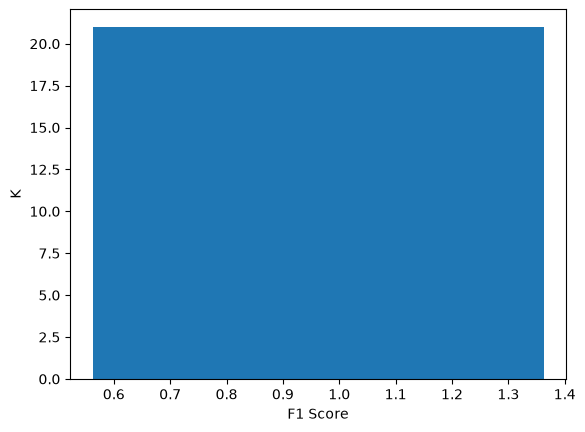

For K=9 
Accuracy is:98.08%
F1 Score is:96.26%
Precions:1.0
Recall:92.78
Confusion Matrix:
[[1035    0]
 [  27  347]]


In [9]:
from sklearn.neighbors import KNeighborsClassifier
import matplotlib.pyplot as plt 
from sklearn.metrics import (
    f1_score,
    precision_score,
    recall_score,
    accuracy_score,
    confusion_matrix
)
list=[0,0,0,0,0,0,0,0]
i=0
for k in [1,3,5,7,9,11,15,21]:
    model=KNeighborsClassifier(n_neighbors=9)
    model.fit(X_train_scaled,y_train)
    y_pred=model.predict(X_test_scaled)
    acc=accuracy_score(y_test,y_pred)
    f1=f1_score(y_test,y_pred)
    list[i]=f1
    print(f"For k={k} Accuracy is:{round(acc*100,2)}% F1 Score is:{round(f1*100,2)}%")
    i+=1

plt.bar(list,[1,3,5,7,9,11,15,21])
plt.xlabel("F1 Score")
plt.ylabel("K")
plt.tight_layout
plt.show()




model=KNeighborsClassifier(n_neighbors=9)
model.fit(X_train_scaled,y_train)
y_pred=model.predict(X_test_scaled)
acc=accuracy_score(y_test,y_pred)
f1=f1_score(y_test,y_pred)
prec=precision_score(y_test,y_pred)
matrix=confusion_matrix(y_test,y_pred)
recall=recall_score(y_test,y_pred)

print(f"For K=9 \nAccuracy is:{round(acc*100,2)}%\nF1 Score is:{round(f1*100,2)}%")
print(f"Precions:{round(prec,2)}\nRecall:{round(recall*100,2)}\nConfusion Matrix:\n{matrix}")
# the k=9 the accuracy and f1 sores are high so our final model will be trianed on the k=9


MODEL COMPARISION TABLE 

In [10]:
table=pd.DataFrame(
    [[prec,l_prec],
    [acc,l_acc],
    [f1,l_f1],
    [recall,l_recall]],
    columns=["KNN","LOGISTIC"],
    index=["PRECISON","ACCURACY","F1 SCORE","RECALL"]
)
print(table)

               KNN  LOGISTIC
PRECISON  1.000000  0.941176
ACCURACY  0.980837  0.745209
F1 SCORE  0.962552  0.081841
RECALL    0.927807  0.042781
